# Eksplorasi Data SIMPLIcity

Notebook ini memeriksa data di folder `data/` dan menampilkan gambarnya sebagai dasar
memilih **ukuran input** dan **parameter augmentasi**. Notebook ini **tidak melatih model**.

Catatan: notebook membaca `data/test` hanya untuk menghitung jumlah dan memeriksa integritas berkas.
Tidak ada gambar test yang ditampilkan, dan tidak ada yang dipakai untuk tuning.

## 1. Setup dan cek perangkat
Import pustaka, tentukan `ROOT` dan `DATA_DIR` dari `Path.cwd()`, lalu cek apakah GPU tersedia.
TensorFlow hanya dipakai di sel ini dan sel 8-9.

In [1]:
import platform
import random
import re
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

try:
    import pandas as pd
    ADA_PANDAS = True
except ImportError:
    pd = None
    ADA_PANDAS = False
    print("pandas tidak terpasang: tabel dicetak sebagai teks biasa.")

# Root repo: kalau notebook dijalankan dari folder common/, naik satu level.
ROOT = Path.cwd()
if ROOT.name == "common":
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
assert DATA_DIR.is_dir(), f"Folder data/ tidak ditemukan di {DATA_DIR}"

SPLITS = ["train", "validation", "test"]
NAMA_KELAS = ["People", "Beach", "Building", "Bus", "Dinosaur",
              "Elephant", "Flower", "Horse", "Mountain", "Food"]
HARAPAN_PER_KELAS = {"train": 50, "validation": 30, "test": 20}
EKSTENSI = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff"}
SEED = 42

print("ROOT     :", ROOT)
print("DATA_DIR :", DATA_DIR)


def cek_perangkat():
    """Cek GPU untuk TensorFlow. Mengembalikan True kalau TensorFlow tersedia."""
    try:
        import tensorflow as tf
    except ImportError:
        print("TensorFlow belum terpasang. Sel 2-7 tetap bisa dijalankan, "
              "tetapi sel 8-9 (pratinjau augmentasi) akan DILEWATI.")
        return False

    versi = tuple(int(x) for x in re.findall(r"\d+", tf.__version__)[:2])
    gpus = tf.config.list_physical_devices("GPU")
    if gpus:
        for gpu in gpus:
            try:
                tf.config.experimental.set_memory_growth(gpu, True)
            except RuntimeError as e:  # terjadi kalau GPU sudah diinisialisasi
                print("Memory growth tidak bisa diatur:", e)
            detail = tf.config.experimental.get_device_details(gpu)
            print("GPU:", detail.get("device_name", gpu.name))
        print("TensorFlow", tf.__version__)
        print("Memakai GPU")
        print("Kalau terjadi out-of-memory (OOM), turunkan batch size.")
    else:
        print("GPU tidak terdeteksi, memakai CPU")
        print("TensorFlow", tf.__version__)
        if platform.system() == "Windows" and versi >= (2, 11):
            print("Catatan: TensorFlow native di Windows tidak mendukung GPU sejak "
                  "versi 2.11. Opsi untuk memakai GPU: jalankan lewat WSL2.")
        print("Saran: eksplorasi dan uji data cukup di CPU, tetapi PELATIHAN model "
              "sebaiknya di Kaggle karena di CPU durasinya akan sangat lama.")
    return True


TF_TERSEDIA = cek_perangkat()

ROOT     : c:\Project_2026\simplicity-cnn-comparison
DATA_DIR : c:\Project_2026\simplicity-cnn-comparison\data
GPU tidak terdeteksi, memakai CPU
TensorFlow 2.20.0
Catatan: TensorFlow native di Windows tidak mendukung GPU sejak versi 2.11. Opsi untuk memakai GPU: jalankan lewat WSL2.
Saran: eksplorasi dan uji data cukup di CPU, tetapi PELATIHAN model sebaiknya di Kaggle karena di CPU durasinya akan sangat lama.


## 2. Struktur folder `data/`
Tampilkan pohon folder 2 level beserta contoh 3 nama berkas pertama. Lalu tentukan apakah tiap split
berisi **subfolder per kelas** atau **berkas campur**.

In [2]:
def kunci_urut(p):
    """Urutkan berdasarkan angka pada nama berkas (2.jpg sebelum 10.jpg)."""
    return (0, int(p.stem), p.name) if p.stem.isdigit() else (1, 0, p.name)


def daftar_gambar(folder):
    return sorted((p for p in folder.iterdir()
                   if p.is_file() and p.suffix.lower() in EKSTENSI), key=kunci_urut)


def daftar_subfolder(folder):
    return sorted(p for p in folder.iterdir() if p.is_dir())


# Pohon 2 level
print("data/")
for split_dir in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    subs, files = daftar_subfolder(split_dir), daftar_gambar(split_dir)
    print(f"├── {split_dir.name}/  ({len(subs)} subfolder, {len(files)} gambar langsung)")
    for s in subs:
        isi = daftar_gambar(s)
        contoh = ", ".join(p.name for p in isi[:3])
        print(f"│   ├── {s.name}/  ({len(isi)} gambar) contoh: {contoh}")
    if files:
        print(f"│   └── contoh berkas: {', '.join(p.name for p in files[:3])}")

# Tentukan jenis struktur
jenis_per_split = {}
for split in SPLITS:
    folder = DATA_DIR / split
    assert folder.is_dir(), f"Folder data/{split} tidak ada"
    subs = [s for s in daftar_subfolder(folder) if daftar_gambar(s)]
    files = daftar_gambar(folder)
    if subs and not files:
        jenis_per_split[split] = "subfolder"
    elif files and not subs:
        jenis_per_split[split] = "campur"
    else:
        jenis_per_split[split] = "tidak jelas"

jenis = set(jenis_per_split.values())
assert len(jenis) == 1 and "tidak jelas" not in jenis, \
    f"Struktur antar-split tidak konsisten: {jenis_per_split}"
STRUKTUR = jenis.pop()

print()
if STRUKTUR == "subfolder":
    FOLDER_KELAS = sorted({s.name for sp in SPLITS for s in daftar_subfolder(DATA_DIR / sp)})
    print("Struktur: SUBFOLDER PER KELAS")
    print("Folder kelas yang ditemukan:", FOLDER_KELAS)
else:
    FOLDER_KELAS = []
    print("Struktur: BERKAS CAMPUR (tidak ada subfolder per kelas)")
    print("Folder kelas yang ditemukan: tidak ada. Kelas akan diturunkan dari kode angka "
          "pada nama berkas (kode // 100).")

data/
├── test/  (0 subfolder, 200 gambar langsung)
│   └── contoh berkas: 80.jpg, 81.jpg, 82.jpg
├── train/  (0 subfolder, 500 gambar langsung)
│   └── contoh berkas: 0.jpg, 1.jpg, 2.jpg
├── validation/  (0 subfolder, 300 gambar langsung)
│   └── contoh berkas: 50.jpg, 51.jpg, 52.jpg

Struktur: BERKAS CAMPUR (tidak ada subfolder per kelas)
Folder kelas yang ditemukan: tidak ada. Kelas akan diturunkan dari kode angka pada nama berkas (kode // 100).


## 3. Jumlah gambar per split per kelas
Harapan: 50 / 30 / 20 per kelas (total 500 / 300 / 200). Untuk struktur berkas campur, kelas diturunkan dari
`kode // 100`. Juga dicek bahwa kode `x00-x49` ada di train, `x50-x79` di validation, dan `x80-x99` di test.

In [3]:
RENTANG_KODE = {"train": range(0, 50), "validation": range(50, 80), "test": range(80, 100)}

data = []           # satu dict per gambar
nama_tak_valid = []
for split in SPLITS:
    folder = DATA_DIR / split
    if STRUKTUR == "subfolder":
        pasangan = [(p, s.name) for s in daftar_subfolder(folder) for p in daftar_gambar(s)]
    else:
        pasangan = []
        for p in daftar_gambar(folder):
            if not p.stem.isdigit() or not 0 <= int(p.stem) <= 999:
                nama_tak_valid.append(f"{split}/{p.name}")
                continue
            pasangan.append((p, NAMA_KELAS[int(p.stem) // 100]))
    for p, kelas in pasangan:
        kode = int(p.stem) if p.stem.isdigit() else None
        data.append({"split": split, "kelas": kelas, "nama": p.name, "kode": kode, "path": p})

assert not nama_tak_valid, f"Nama berkas bukan kode angka 0-999: {nama_tak_valid[:10]}"

urutan_kelas = NAMA_KELAS if STRUKTUR == "campur" else FOLDER_KELAS
hitung = Counter((d["kelas"], d["split"]) for d in data)

if ADA_PANDAS:
    tabel = pd.DataFrame([[hitung[(k, s)] for s in SPLITS] for k in urutan_kelas],
                         index=urutan_kelas, columns=SPLITS)
    tabel.loc["TOTAL"] = tabel.sum()
    display(tabel)
else:
    print(f"{'kelas':<10}" + "".join(f"{s:>12}" for s in SPLITS))
    for k in urutan_kelas:
        print(f"{k:<10}" + "".join(f"{hitung[(k, s)]:>12}" for s in SPLITS))

# Assert jumlah
assert len(urutan_kelas) == 10, f"Harus ada 10 kelas, ditemukan {len(urutan_kelas)}"
for split, harap in HARAPAN_PER_KELAS.items():
    salah = {k: hitung[(k, split)] for k in urutan_kelas if hitung[(k, split)] != harap}
    assert not salah, f"{split}: tiap kelas harus {harap} gambar, yang berbeda: {salah}"
    total = sum(hitung[(k, split)] for k in urutan_kelas)
    assert total == harap * 10, f"{split}: total harus {harap * 10}, ditemukan {total}"

# Assert rentang kode (kalau nama berkas berupa angka)
salah_rentang = [f"{d['split']}/{d['nama']}" for d in data
                 if d["kode"] is not None and d["kode"] % 100 not in RENTANG_KODE[d["split"]]]
assert not salah_rentang, f"Kode di luar rentang split-nya: {salah_rentang[:10]}"
print("OK: jumlah per kelas 50/30/20, total 500/300/200, dan rentang kode sesuai split.")

,train,validation,test
People,50,30,20
Beach,50,30,20
Building,50,30,20
Bus,50,30,20
Dinosaur,50,30,20
Elephant,50,30,20
Flower,50,30,20
Horse,50,30,20
Mountain,50,30,20
Food,50,30,20


OK: jumlah per kelas 50/30/20, total 500/300/200, dan rentang kode sesuai split.


## 4. Integritas data
(a) Tidak boleh ada nama berkas yang sama di dua split (kebocoran data). (b) Setiap gambar harus bisa dibuka
dengan Pillow (`Image.verify`). (c) Semua gambar harus bermode RGB. Ukuran tiap gambar juga dicatat untuk sel 5.

In [4]:
# (a) Kebocoran: nama berkas sama di lebih dari satu split
split_per_nama = defaultdict(set)
for d in data:
    split_per_nama[d["nama"]].add(d["split"])
bocor = {n: sorted(s) for n, s in split_per_nama.items() if len(s) > 1}

# (b) dan (c) Buka setiap gambar
rusak, bukan_rgb = [], []
for d in data:
    try:
        with Image.open(d["path"]) as im:
            im.verify()                    # verify() membuat objek tidak bisa dipakai lagi
        with Image.open(d["path"]) as im:  # jadi buka ulang untuk membaca mode dan ukuran
            d["mode"], (d["w"], d["h"]) = im.mode, im.size
            im.load()
    except Exception as e:
        rusak.append(f"{d['split']}/{d['nama']}: {e}")
        d["mode"], d["w"], d["h"] = None, None, None
        continue
    if d["mode"] != "RGB":
        bukan_rgb.append(f"{d['split']}/{d['nama']} ({d['mode']})")

print(f"(a) Nama berkas di lebih dari satu split : {len(bocor)}", bocor if bocor else "")
print(f"(b) Gambar rusak / gagal dibuka           : {len(rusak)}")
for r in rusak:
    print("    -", r)
print(f"(c) Gambar bukan RGB                      : {len(bukan_rgb)}")
for r in bukan_rgb:
    print("    -", r)
print("Mode yang ditemukan:", dict(Counter(d["mode"] for d in data)))
if not (bocor or rusak or bukan_rgb):
    print("OK: tidak ada kebocoran, tidak ada gambar rusak, semua RGB.")

(a) Nama berkas di lebih dari satu split : 0 
(b) Gambar rusak / gagal dibuka           : 0
(c) Gambar bukan RGB                      : 0
Mode yang ditemukan: {'RGB': 1000}
OK: tidak ada kebocoran, tidak ada gambar rusak, semua RGB.


## 5. Ukuran dan orientasi gambar
Distribusi (lebar, tinggi) dan orientasi seluruh gambar, untuk melihat apakah resize langsung ke persegi akan
menggepengkan gambar. Lalu persentase portrait per split per kelas. Kelas dengan selisih antar-split lebih dari
15 poin persentase diberi tanda.

Ukuran (lebar x tinggi) terbanyak:


,ukuran,jumlah,persen
0,384x256,800,80.0%
1,256x384,200,20.0%


Jumlah ukuran berbeda: 2
Orientasi: {'portrait': '200 (20.0%)', 'landscape': '800 (80.0%)'}
Rasio lebar/tinggi: min 0.67, median 1.50, max 1.50
Resize langsung ke persegi mengubah rasio landscape 1.50:1 menjadi 1:1.


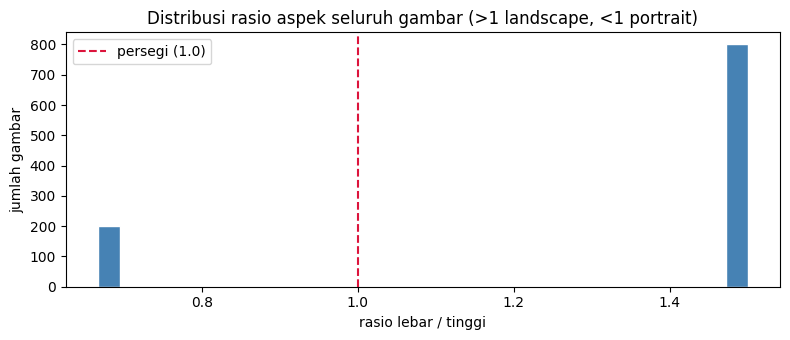


Persentase gambar portrait (%) per split per kelas:


,train,validation,test,selisih_maks,tanda
kelas,,,,,
People,36.0,46.7,30.0,16.7,<< selisih > 15 poin
Beach,14.0,16.7,25.0,11.0,
Building,28.0,26.7,35.0,8.3,
Bus,0.0,0.0,10.0,10.0,
Dinosaur,0.0,0.0,0.0,0.0,
Elephant,12.0,10.0,30.0,20.0,<< selisih > 15 poin
Flower,0.0,16.7,15.0,16.7,<< selisih > 15 poin
Horse,8.0,40.0,20.0,32.0,<< selisih > 15 poin
Mountain,36.0,33.3,35.0,2.7,


Kelas yang ditandai: ['People', 'Elephant', 'Flower', 'Horse', 'Food']


In [5]:
valid = [d for d in data if d["w"] is not None]
for d in valid:
    d["orientasi"] = ("landscape" if d["w"] > d["h"]
                      else "portrait" if d["h"] > d["w"] else "persegi")

ukuran = Counter((d["w"], d["h"]) for d in valid)
orient = Counter(d["orientasi"] for d in valid)
rasio = np.array([d["w"] / d["h"] for d in valid])

print("Ukuran (lebar x tinggi) terbanyak:")
if ADA_PANDAS:
    display(pd.DataFrame([(f"{w}x{h}", n, f"{100 * n / len(valid):.1f}%")
                          for (w, h), n in ukuran.most_common(10)],
                         columns=["ukuran", "jumlah", "persen"]))
else:
    for (w, h), n in ukuran.most_common(10):
        print(f"  {w}x{h}: {n}")
print(f"Jumlah ukuran berbeda: {len(ukuran)}")
print("Orientasi:", {k: f"{v} ({100 * v / len(valid):.1f}%)" for k, v in orient.items()})
print(f"Rasio lebar/tinggi: min {rasio.min():.2f}, median {np.median(rasio):.2f}, max {rasio.max():.2f}")
print(f"Resize langsung ke persegi mengubah rasio landscape {np.median(rasio[rasio > 1]):.2f}:1 "
      "menjadi 1:1." if (rasio > 1).any() else "")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(rasio, bins=30, color="steelblue", edgecolor="white")
ax.axvline(1.0, color="crimson", ls="--", label="persegi (1.0)")
ax.set_xlabel("rasio lebar / tinggi")
ax.set_ylabel("jumlah gambar")
ax.set_title("Distribusi rasio aspek seluruh gambar (>1 landscape, <1 portrait)")
ax.legend()
plt.tight_layout()
plt.show()

# Persentase portrait per split per kelas
AMBANG_SELISIH = 15
baris = []
for k in urutan_kelas:
    persen = []
    for s in SPLITS:
        grup = [d for d in valid if d["kelas"] == k and d["split"] == s]
        persen.append(100 * sum(d["orientasi"] == "portrait" for d in grup) / max(len(grup), 1))
    selisih = max(persen) - min(persen)
    baris.append([k, *[round(p, 1) for p in persen], round(selisih, 1),
                  "<< selisih > 15 poin" if selisih > AMBANG_SELISIH else ""])

kolom = ["kelas", *SPLITS, "selisih_maks", "tanda"]
print("\nPersentase gambar portrait (%) per split per kelas:")
if ADA_PANDAS:
    display(pd.DataFrame(baris, columns=kolom).set_index("kelas"))
else:
    for b in baris:
        print(b)
ditandai = [b[0] for b in baris if b[-1]]
print("Kelas yang ditandai:", ditandai if ditandai else "tidak ada")

## 6. Contoh gambar train
Grid 10 kelas x 10 gambar acak dari **train** (seed tetap). Di bawahnya, grid yang lebih besar untuk Beach,
Mountain, dan People, tiga kelas yang paling mungkin tertukar.

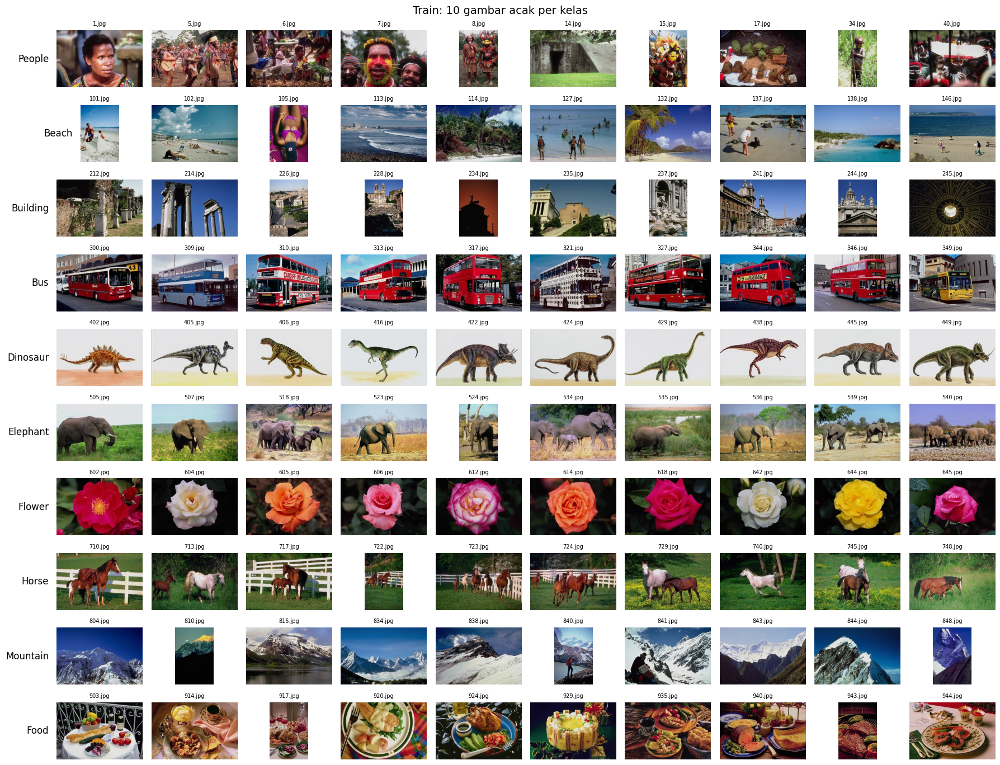

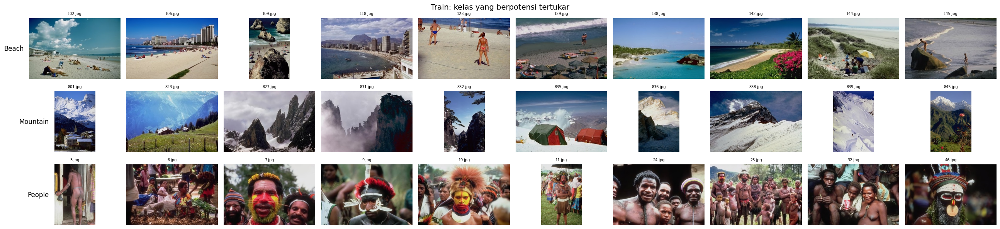

In [6]:
def muat(path):
    with Image.open(path) as im:
        return im.convert("RGB")


def tampilkan_grid(kelas_list, n_kolom, ukuran_sel, judul, seed=SEED):
    rng = random.Random(seed)
    fig, axes = plt.subplots(len(kelas_list), n_kolom,
                             figsize=(n_kolom * ukuran_sel, len(kelas_list) * ukuran_sel * 0.75))
    axes = np.atleast_2d(axes)
    for i, k in enumerate(kelas_list):
        kandidat = [d for d in data if d["split"] == "train" and d["kelas"] == k]
        pilihan = sorted(rng.sample(kandidat, min(n_kolom, len(kandidat))), key=lambda d: kunci_urut(d["path"]))
        for j, ax in enumerate(axes[i]):
            ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(False)
            if j < len(pilihan):
                ax.imshow(muat(pilihan[j]["path"]))
                ax.set_title(pilihan[j]["nama"], fontsize=7)
        axes[i, 0].set_ylabel(k, fontsize=12, rotation=0, ha="right", va="center", labelpad=10)
    plt.tight_layout()
    fig.suptitle(judul, fontsize=14, y=1.01)
    plt.show()


tampilkan_grid(urutan_kelas, 10, 1.8, "Train: 10 gambar acak per kelas")

kelas_mirip = [k for k in ["Beach", "Mountain", "People"] if k in urutan_kelas]
tampilkan_grid(kelas_mirip, 10, 2.6, "Train: kelas yang berpotensi tertukar", seed=SEED + 1)

### Temuan visual

## 7. Perbandingan cara resize ke 224x224
Satu gambar landscape dan satu gambar portrait dari train dibandingkan dalam empat versi: asli, **stretch**
(resize langsung), **crop** (potong tengah mengikuti rasio), dan **padding** (letterbox ke persegi dengan border
abu-abu netral). Sel ini hanya memakai Pillow.

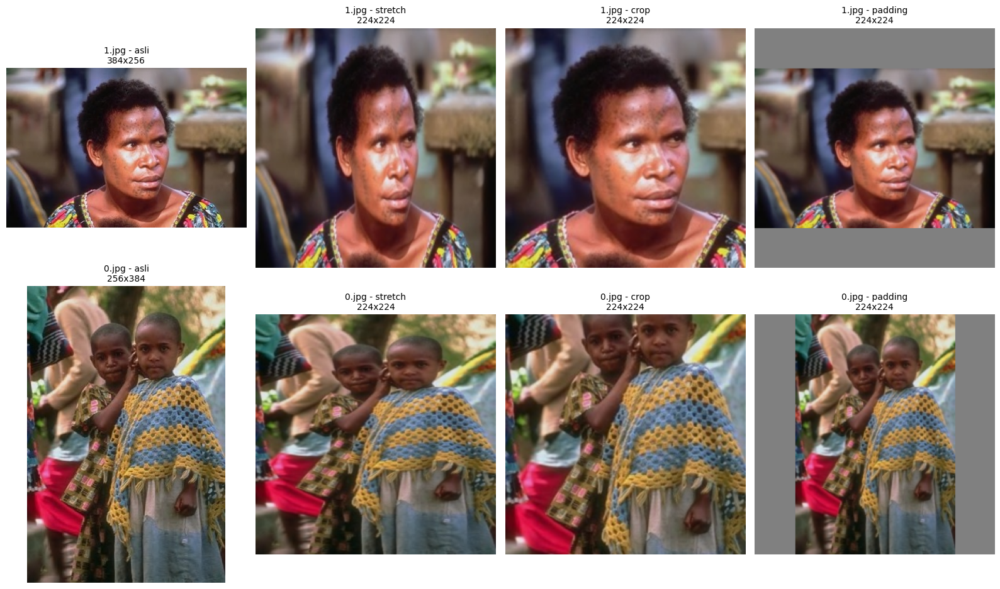

In [7]:
UKURAN_TARGET = (224, 224)
WARNA_PADDING = (128, 128, 128)
METODE = Image.Resampling.BILINEAR


def resize_stretch(im):
    return im.resize(UKURAN_TARGET, METODE)


def resize_crop(im):
    return ImageOps.fit(im, UKURAN_TARGET, method=METODE, centering=(0.5, 0.5))


def resize_padding(im):
    return ImageOps.pad(im, UKURAN_TARGET, method=METODE, color=WARNA_PADDING)


CARA_RESIZE = {"stretch": resize_stretch, "crop": resize_crop, "padding": resize_padding}

contoh = []
for o in ["landscape", "portrait"]:
    calon = [d for d in valid if d["split"] == "train" and d["orientasi"] == o]
    if calon:
        contoh.append(calon[0])
    else:
        print(f"Tidak ada gambar {o} di train, dilewati.")

fig, axes = plt.subplots(len(contoh), 4, figsize=(16, 4.8 * len(contoh)), squeeze=False)
for i, d in enumerate(contoh):
    asli = muat(d["path"])
    versi = [("asli", asli)] + [(nama, f(asli)) for nama, f in CARA_RESIZE.items()]
    for ax, (nama, im) in zip(axes[i], versi):
        ax.imshow(im)
        ax.set_title(f"{d['nama']} - {nama}\n{im.size[0]}x{im.size[1]}", fontsize=10)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Kandidat parameter augmentasi
Semua parameter ada di bagian atas sel agar mudah diubah. Layer augmentasi Keras dibangun dengan seed tetap.
Sel ini dilewati kalau TensorFlow tidak tersedia.

In [12]:
# ===== Kandidat parameter (ubah di sini) =====
FLIP = "horizontal"
ROTASI_DERAJAT = 15
ZOOM = (-0.2, 0.0)      # Keras: nilai negatif = zoom in (sampai 20%), 0 = tanpa zoom out
BRIGHTNESS = 0.15
CONTRAST = 0.15
TRANSLASI = 0.05        # geser maksimal 5% lebar/tinggi
CARA_RESIZE_PRATINJAU = "crop"   # "stretch" / "crop" / "padding" (fungsi dari sel 7)
# =============================================

if not TF_TERSEDIA:
    print("TensorFlow tidak tersedia: sel 8 dilewati.")
else:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers

    keras.utils.set_random_seed(SEED)
    augmentasi = keras.Sequential([
        layers.RandomFlip(FLIP, seed=SEED),
        layers.RandomRotation(ROTASI_DERAJAT / 360, fill_mode="reflect", seed=SEED),
        layers.RandomZoom(height_factor=ZOOM, width_factor=ZOOM, fill_mode="reflect", seed=SEED),
        layers.RandomTranslation(TRANSLASI, TRANSLASI, fill_mode="reflect", seed=SEED),
        layers.RandomBrightness(BRIGHTNESS, value_range=(0, 255), seed=SEED),
        layers.RandomContrast(CONTRAST, seed=SEED),
    ], name="augmentasi")

    for lyr in augmentasi.layers:
        print(f"- {lyr.__class__.__name__}")
    print(f"Rotasi maks {ROTASI_DERAJAT} derajat (faktor {ROTASI_DERAJAT / 360:.4f}), zoom {ZOOM}, "
          f"translasi {TRANSLASI}, brightness {BRIGHTNESS}, contrast {CONTRAST}")

- RandomFlip
- RandomRotation
- RandomZoom
- RandomTranslation
- RandomBrightness
- RandomContrast
Rotasi maks 15 derajat (faktor 0.0417), zoom (-0.2, 0.0), translasi 0.05, brightness 0.15, contrast 0.15


## 9. Pratinjau augmentasi
Satu gambar train per kelas (10 baris): gambar asli lalu 8 versi hasil augmentasi (`training=True`).
Pastikan semua versi masih jelas terlihat sebagai kelasnya.

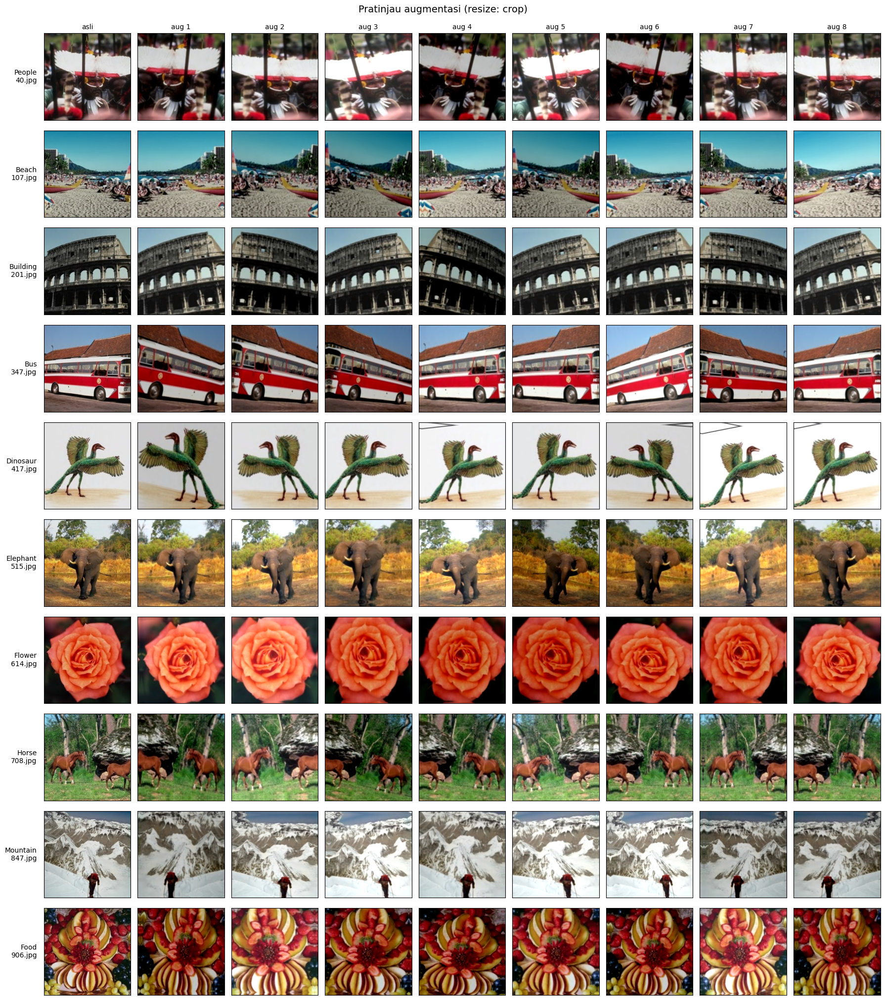

In [13]:
if not TF_TERSEDIA:
    print("TensorFlow tidak tersedia: sel 9 dilewati.")
else:
    N_AUG = 8
    rng = random.Random(SEED)
    wakil = [rng.choice([d for d in data if d["split"] == "train" and d["kelas"] == k])
             for k in urutan_kelas]
    resize = CARA_RESIZE[CARA_RESIZE_PRATINJAU]
    x = np.stack([np.asarray(resize(muat(d["path"])), dtype="float32") for d in wakil])

    hasil = [np.clip(np.asarray(augmentasi(x, training=True)), 0, 255).astype("uint8")
             for _ in range(N_AUG)]

    fig, axes = plt.subplots(len(wakil), N_AUG + 1, figsize=(2.0 * (N_AUG + 1), 2.0 * len(wakil)))
    for i, d in enumerate(wakil):
        gambar = [x[i].astype("uint8")] + [h[i] for h in hasil]
        for j, ax in enumerate(axes[i]):
            ax.imshow(gambar[j])
            ax.set_xticks([]); ax.set_yticks([])
            if i == 0:
                ax.set_title("asli" if j == 0 else f"aug {j}", fontsize=10)
        axes[i, 0].set_ylabel(f"{d['kelas']}\n{d['nama']}", fontsize=10,
                              rotation=0, ha="right", va="center", labelpad=10)
    plt.tight_layout()
    fig.suptitle(f"Pratinjau augmentasi (resize: {CARA_RESIZE_PRATINJAU})", fontsize=14, y=1.01)
    plt.show()

## 10. Ringkasan keputusan

- Ukuran input: 224x224
- Cara resize (stretch/crop): padding (letterbox ke persegi, border abu-abu netral). Stretch menggepengkan proporsi objek (landscape jadi ramping, portrait jadi gemuk); crop berisiko memotong informasi penting di tepi gambar.
- Parameter augmentasi final (rotasi, zoom, brightness, contrast): flip horizontal, rotasi 15 derajat, zoom (-0.2, 0.0), translasi 0.05, brightness 0.15, contrast 0.15. Semua versi pratinjau masih jelas terlihat sebagai kelasnya; brightness membantu gambar yang gelap.
- Kelas yang berpotensi tertukar dan catatannya: Beach dengan People (banyak foto pantai berisi orang). People sendiri masih jelas terlihat sebagai manusia, dan Mountain tampak cukup unik. Dugaan lain untuk dicek di confusion matrix: Beach dengan Mountain, Horse dengan Elephant, Building dengan Bus.
- Temuan integritas data (jumlah, kebocoran, gambar rusak): data terbagi merata 50/30/20 per kelas (500/300/200), tidak ada kebocoran antar-split, tidak ada gambar rusak, semua 1000 gambar RGB, dan nama berkas unik.
  - Hanya ada dua ukuran gambar: 384x256 (landscape, 80%) dan 256x384 (portrait, 20%).
  - Persentase portrait tidak seimbang antar-split (selisih > 15 poin) pada People, Elephant, Flower, Horse, dan Food (paling besar Horse: 8% di train, 40% di validation).